# 04 · Decoding (machine learning on brains)  (⏱ ~75 min)

**Concept:** instead of asking "which voxels respond to faces?" (encoding/GLM), ask "can I *predict* what the subject was looking at from the brain activity?" That's **decoding** (a.k.a. MVPA).

You need: `X` (samples x voxels), `y` (labels), and a **cross-validation scheme that respects the data's structure**. fMRI samples within a run are correlated, so you split by *run/session*, not randomly.

Nilearn's `decoding.Decoder` wraps masker + scikit-learn estimator + CV in one object.

**Gallery to read after your attempt:** `00_tutorials/plot_decoding_tutorial.py` (the gentlest intro), then in `02_decoding`: `plot_haxby_anova_svm.py` (this exact face-vs-house task), `plot_haxby_understand_decoder.py` (what `Decoder` does under the hood, step by step), `plot_haxby_different_estimators.py`, `plot_haxby_searchlight.py`. Also `07_advanced/plot_advanced_decoding_scikit.py` for doing it in plain scikit-learn.

In [10]:
!pip install -q nilearn
import nilearn, numpy as np, pandas as pd, matplotlib.pyplot as plt
import sklearn.model_selection
print("nilearn", nilearn.__version__)

nilearn 0.14.1


In [3]:
from nilearn import datasets, decoding, image, plotting
from sklearn.model_selection import LeaveOneGroupOut
haxby = datasets.fetch_haxby(subjects=[2])
labels = pd.read_csv(haxby.session_target[0], sep=" ")

[fetch_haxby] Added README.md to /root/nilearn_data

[fetch_haxby] Dataset created in /root/nilearn_data/haxby2001

[fetch_haxby] Downloading data from https://www.nitrc.org/frs/download.php/7868/mask.nii.gz ...

[fetch_haxby]  ...done. (1 seconds, 0 min)

[fetch_haxby] Downloading data from http://data.pymvpa.org/datasets/haxby2001/MD5SUMS ...

[fetch_haxby]  ...done. (1 seconds, 0 min)

... (25 outputs left out)

[fetch_haxby] Downloaded 281976832 of 291168628 bytes (96.8%%, 00 HR 00 MIN 01 SEC remaining)

[fetch_haxby]  ...done. (28 seconds, 0 min)

[fetch_haxby] Extracting data from /root/nilearn_data/haxby2001/3d2c7644e96a21be22fab60f69663a15/subj2-2010.01.14.tar.gz...

[fetch_haxby] .. done.

## Exercises
- **Ex 1.** Look at `labels`: it has a `labels` column and a `chunks` column. What do you think `chunks` is for? (Predict, then check the gallery Haxby example.)
- **Ex 2.** Restrict to two conditions, `face` vs `house`, and drop the `rest` scans: build a boolean mask over the time axis and apply it with `image.index_img`.
- **Ex 3.** Build a `decoding.Decoder(estimator="svc", mask=..., cv=LeaveOneGroupOut(), scoring="accuracy", standardize="zscore_sample")`. Fit with `groups=chunks`. Read `decoder.cv_scores_`. What's chance level here? Is your result convincing?
- **Ex 4.** Compare with a baseline: `estimator="dummy_classifier"`. Why should you always run a dummy baseline?
- **Ex 5.** Plot the model weights (`decoder.coef_img_`) with `plot_stat_map`. *Careful:* explain in one sentence why a high weight is not the same as "this voxel is where the brain encodes faces".
- **Ex 6 (leakage thought experiment).** Imagine you did random 5-fold CV mixing scans from the same run, or standardised using all the data before splitting. What would happen to the accuracy and why? (Try random CV and compare, it's an eye-opener.)
- **Ex 7 (stretch).** Swap `svc` for `logistic_l1`, or add `screening_percentile`. Read about `SpaceNet` and `searchlight` in the gallery.

- **Ex 1.** Look at `labels`: it has a `labels` column and a `chunks` column. What do you think `chunks` is for? (Predict, then check the gallery Haxby example.)

In [8]:
#print(labels.head())
print(labels["labels"].value_counts())
#the chunks help assign a label to a scanning session of the MRI

labels
rest            588
scissors        108
face            108
cat             108
shoe            108
house           108
scrambledpix    108
bottle          108
chair           108
Name: count, dtype: int64


- **Ex 2.** Restrict to two conditions, `face` vs `house`, and drop the `rest` scans: build a boolean mask over the time axis and apply it with `image.index_img`.

In [4]:
filtered_labels = labels[(labels["labels"] == "face") | (labels["labels"] == "house")]
print(filtered_labels)

     labels  chunks
21     face       0
22     face       0
23     face       0
24     face       0
25     face       0
...     ...     ...
1398   face      11
1399   face      11
1400   face      11
1401   face      11
1402   face      11

[216 rows x 2 columns]


In [5]:
filtered_img = nilearn.image.index_img(haxby.func[0], np.array(filtered_labels.index))
print(filtered_img.shape)

(40, 64, 64, 216)


- **Ex 3.** Build a `decoding.Decoder(estimator="svc", mask=..., cv=LeaveOneGroupOut(), scoring="accuracy", standardize="zscore_sample")`. Fit with `groups=chunks`. Read `decoder.cv_scores_`. What's chance level here? Is your result convincing?

In [35]:
svc_decoder = decoding.Decoder(estimator="svc", mask=haxby.mask, cv=LeaveOneGroupOut(), scoring="accuracy", standardize="zscore_sample")
svc_decoder.fit(filtered_img, filtered_labels["labels"], groups=filtered_labels["chunks"])

Decoder(cv=LeaveOneGroupOut(), mask='/root/nilearn_data/haxby2001/mask.nii.gz',
        scoring='accuracy', standardize='zscore_sample')

In [36]:
print(svc_decoder.cv_scores_)
print(np.mean(svc_decoder.cv_scores_['face']))
print(np.mean(svc_decoder.cv_scores_['house']))
#Chance in a binary with evenly weighted samples would be .5. I'm getting .94, which is far above chance.

{np.str_('face'): [0.9444444444444444, 1.0, 1.0, 0.9444444444444444, 0.7222222222222222, 1.0, 0.8888888888888888, 1.0, 0.8333333333333334, 1.0, 0.9444444444444444, 1.0], np.str_('house'): [0.9444444444444444, 1.0, 1.0, 0.9444444444444444, 0.7222222222222222, 1.0, 0.8888888888888888, 1.0, 0.8333333333333334, 1.0, 0.9444444444444444, 1.0]}
0.9398148148148149
0.9398148148148149


- **Ex 4.** Compare with a baseline: `estimator="dummy_classifier"`. Why should you always run a dummy baseline?

In [37]:
dummy_decoder = decoding.Decoder(estimator="dummy_classifier", mask=haxby.mask, cv=LeaveOneGroupOut(), scoring="accuracy", standardize="zscore_sample")
dummy_decoder.fit(filtered_img, filtered_labels["labels"], groups=filtered_labels["chunks"])
print(dummy_decoder.cv_scores_)
print(np.mean(dummy_decoder.cv_scores_['face']))
print(np.mean(dummy_decoder.cv_scores_['house']))
#To verify that your results are far above chance

{np.str_('face'): [0.6111111111111112, 0.6111111111111112, 0.6111111111111112, 0.3888888888888889, 0.6111111111111112, 0.6111111111111112, 0.3888888888888889, 0.6111111111111112, 0.6111111111111112, 0.3888888888888889, 0.3888888888888889, 0.3888888888888889], np.str_('house'): [0.6111111111111112, 0.6111111111111112, 0.6111111111111112, 0.3888888888888889, 0.6111111111111112, 0.6111111111111112, 0.3888888888888889, 0.6111111111111112, 0.6111111111111112, 0.3888888888888889, 0.3888888888888889, 0.3888888888888889]}
0.5185185185185186
0.5185185185185186


- **Ex 5.** Plot the model weights (`decoder.coef_img_`) with `plot_stat_map`. *Careful:* explain in one sentence why a high weight is not the same as "this voxel is where the brain encodes faces".

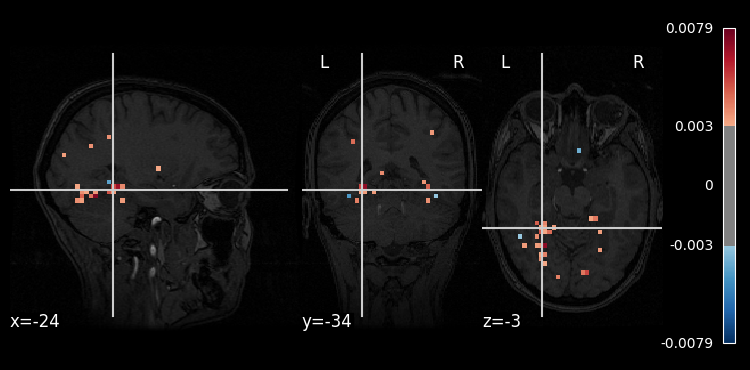

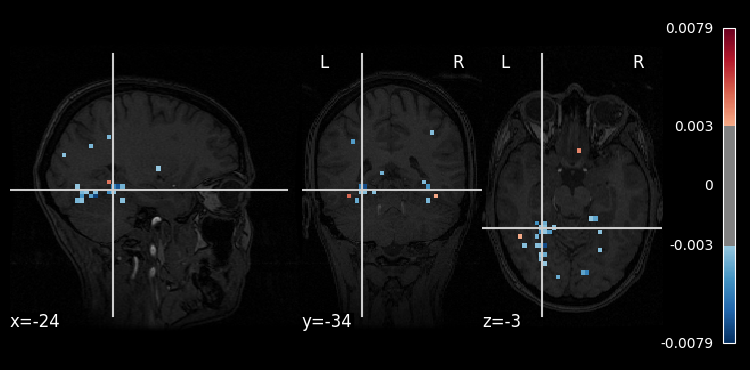

In [42]:
nilearn.plotting.plot_stat_map(svc_decoder.coef_img_["face"], bg_img=haxby.anat[0], threshold=0.003)
nilearn.plotting.plot_stat_map(svc_decoder.coef_img_["house"], bg_img=haxby.anat[0], threshold=0.003)
#This is simply comparing two different labels.
#This weight would be "these voxels are more important to classifying 'face' as opposed to 'house'",
#not, "this is where face is encoded".

- **Ex 6 (leakage thought experiment).** Imagine you did random 5-fold CV mixing scans from the same run, or standardised using all the data before splitting. What would happen to the accuracy and why? (Try random CV and compare, it's an eye-opener.)

In [12]:
cv_decoder = decoding.Decoder(estimator="svc", mask=haxby.mask, cv=sklearn.model_selection.KFold(n_splits=5, shuffle=True), scoring="accuracy", standardize="zscore_sample")
cv_decoder.fit(filtered_img, filtered_labels["labels"])
print(cv_decoder.cv_scores_)
print(np.mean(cv_decoder.cv_scores_['face']))
print(np.mean(cv_decoder.cv_scores_['house']))
#random mixing allows for very similar scans from the same run to leak into the validation set

{np.str_('face'): [1.0, 0.9767441860465116, 0.9767441860465116, 1.0, 1.0], np.str_('house'): [1.0, 0.9767441860465116, 0.9767441860465116, 1.0, 1.0]}
0.9906976744186047
0.9906976744186047


## Check your understanding
- Why leave-one-run-out rather than random k-fold?  
A: Each run should be counted as a group, as samples within a run are too similar and will cause the model to falsely validate as quite high in accuracy.
- Why does `n_features >> n_samples` make regularisation and feature screening important here?  
A: The error of a classifier grows as the number of features gets much larger. Thus feature selection becomes much more important as feature number grows.
- What's the difference between *decoding accuracy* and *a map of where information lives*?  
A: Decoding accuracy really only tells you "This section of the brain is important to telling if the brain is doing action A vs action B", but doesn't tell you if the information lives there or not. It tells you what voxels are important to decode "house" vs "face" not where those two things live.

## Industry/research angle
Decoding underlies brain-computer interfaces, "mind-reading" studies, and clinical prediction models (e.g. predicting treatment response). The leakage lessons transfer directly to any ML job.